# Sea Angel Detector: Transfer Learning with ResNet-18

A step-by-step tutorial: download deep-sea images of sea angels from FathomNet, crop them into a small
dataset, fine-tune a pretrained CNN to answer **"sea angel or not?"**, and then look inside the model
to see what it learned.

**Steps**

1. Setup
2. Get the data: download, take inventory, look at the boxes
3. Build the dataset: crop sea angels, add "not sea angel" examples
4. Prepare for training: split and augment
5. Train: build the model, train the new head, check the results
6. Look inside: Grad-CAM heatmaps and feature maps
7. Fine-tune deeper and compare
8. Save and reload

**Before you start:** turn on a GPU with **Runtime → Change runtime type → T4 GPU**, then run the cells top to bottom.

## 1. Setup



In [ ]:
!pip install -q fathomnet grad-cam

import copy, json, os, random
from collections import Counter
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import requests
import torch
import torch.nn as nn
from PIL import Image, ImageFile
from sklearn.metrics import precision_score, recall_score
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from fathomnet.api import images, taxa
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

ImageFile.LOAD_TRUNCATED_IMAGES = True   # don't crash on a partly downloaded image

# Paths
DATA_DIR = "/content/fathomnet"          # COCO labels from FathomNet
IMG_DIR  = f"{DATA_DIR}/images"          # full-size frames
CROP_DIR = "/content/crops"              # one folder per class: sea_angel/, not_sea_angel/

# Dataset settings
N_WATER       = 223                      # empty-water negatives (about 110 balances the classes once look-alikes are added)
LOOKALIKES    = ["Thecosomata", "Ctenophora", "Larvacea"]   # sea butterflies, comb jellies, larvaceans
PER_LOOKALIKE = 40                       # crops per look-alike group
SEED          = 42                       # fixed seed so reruns give the same split

random.seed(SEED)
torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
device: cuda


## 2. Get the data

### 2.1 Download every sea angel

Downloads all images labeled with **Gymnosomata** (the sea angel order) or anything under it in the
taxonomy (`--taxa fathomnet`), and writes their bounding boxes to one COCO file.

In [ ]:
!fathomnet-generate --output {DATA_DIR} --img-download {IMG_DIR} \
    --concepts 'Gymnosomata' --taxa fathomnet --format coco -v

INFO:root:Creating output directory /content/fathomnet
INFO:root:Creating output directory /content/fathomnet/images
INFO:root:Successfully parsed flags
INFO:root:Concept(s) specified:
INFO:root:- Abranchaea
INFO:root:- Abranchaea chinensis
INFO:root:- Anopsia
INFO:root:- Anopsiidae
INFO:root:- Cephalobrachia
INFO:root:- Cephalobrachia bonnevii
INFO:root:- Cephalobrachia macrochaeta
INFO:root:- Cirrifer
INFO:root:- Cirrifer paradoxus
INFO:root:- Clione
INFO:root:- Clione antarctica
INFO:root:- Clione aurantiaca
INFO:root:- Clione borealis
INFO:root:- Clione dalli
INFO:root:- Clione elegantissima
INFO:root:- Clione filifera
INFO:root:- Clione gracilis
INFO:root:- Clione ikuoi
INFO:root:- Clione japonica
INFO:root:- Clione kinkaidi
INFO:root:- Clione lebouri
INFO:root:- Clione limacina
INFO:root:- Clione limacina antarctica
INFO:root:- Clione limacina australis
INFO:root:- Clione limacina f. meridionalis
INFO:root:- Clione limacina limacina
INFO:root:- Clione limacina var. meridionalis
I

### 2.2 Take inventory

Loads the COCO file and counts images, boxes, and boxes per label, so you know what you actually have
before building anything.

In [ ]:
with open(f"{DATA_DIR}/dataset.json") as f:
    coco = json.load(f)

id_to_name = {c["id"]: c["name"] for c in coco["categories"]}
box_counts = Counter(id_to_name[a["category_id"]] for a in coco["annotations"])
img_counts = Counter(a["image_id"] for a in coco["annotations"])

print(len(coco["images"]), "images |", len(coco["annotations"]), "boxes")
print(sum(n > 1 for n in img_counts.values()), "images with more than one box\n")
[print(f"{n:>5}  {name}") for name, n in box_counts.most_common()];

223 images | 225 boxes
2 images with more than one box

   64  Thliptodon
   57  Clione limacina
   46  Notobranchaea macdonaldi
   24  Notobranchaea grandis
   14  Notobranchaea
    8  Clione
    6  Pneumodermopsis
    3  Gymnosomata
    3  Massya longecirrata


### 2.3 Look at the boxes

Draws the labeled boxes on 9 images. Check that the green boxes sit on the animals, and notice how small
and faint the sea angels are.

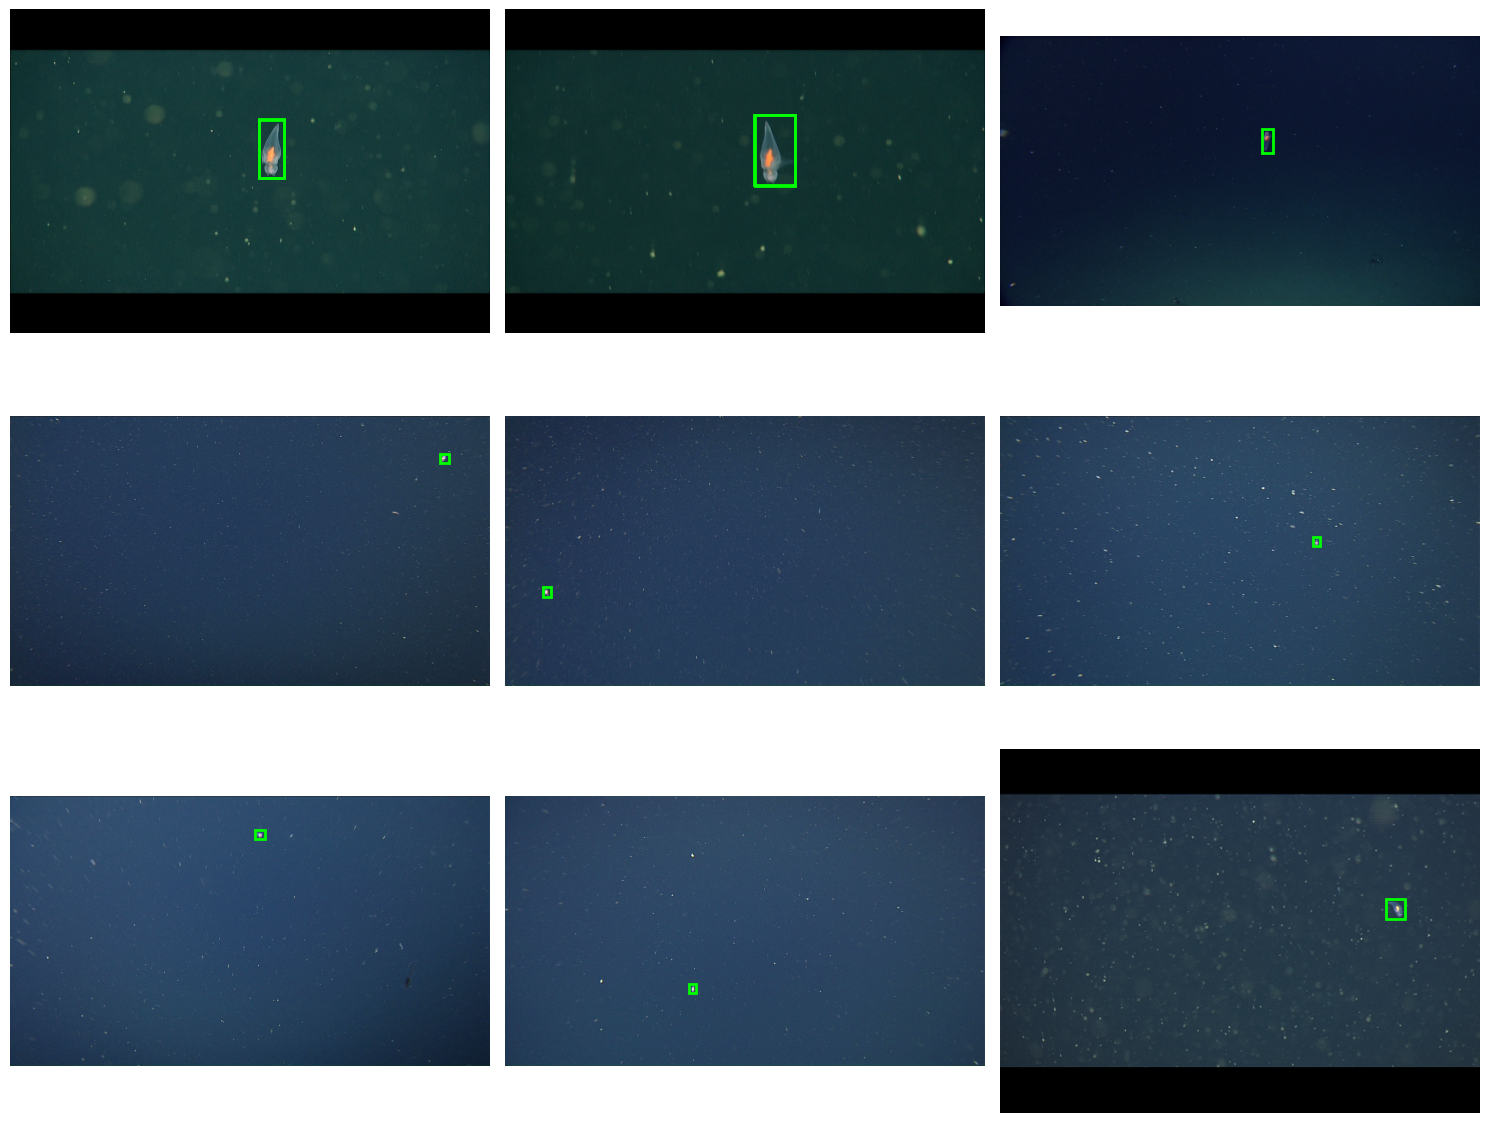

In [ ]:
imgs = coco["images"][:9]
boxes_by_img = {i["id"]: [a for a in coco["annotations"] if a["image_id"] == i["id"]] for i in imgs}

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, img in zip(axes.flat, imgs):
    ax.imshow(Image.open(f"{IMG_DIR}/{img['file_name']}"))
    [ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, color="lime", lw=2))
     for x, y, w, h in (a["bbox"] for a in boxes_by_img[img["id"]])]
    ax.axis("off")
plt.tight_layout()

## 3. Build the dataset

### 3.1 Crop the sea angels

Cuts every box out into its own 224×224 image, with 20% padding so the model sees a little water around
the animal. The padded box is kept inside the frame.

In [ ]:
os.makedirs(f"{CROP_DIR}/sea_angel", exist_ok=True)
img_by_id = {i["id"]: i for i in coco["images"]}

for a in coco["annotations"]:
    img = img_by_id[a["image_id"]]
    x, y, w, h = a["bbox"]
    pad = 0.2 * max(w, h)
    box = (max(0, x - pad), max(0, y - pad),
           min(img["width"], x + w + pad), min(img["height"], y + h + pad))
    Image.open(f"{IMG_DIR}/{img['file_name']}").convert("RGB") \
        .crop(box).resize((224, 224)).save(f"{CROP_DIR}/sea_angel/{a['id']}.png")

print(len(os.listdir(f"{CROP_DIR}/sea_angel")), "sea angel crops")

225 sea angel crops


### 3.2 Negatives, part 1: empty water

The model also needs examples of what a sea angel is **not**. This cuts random 224×224 patches from the
same frames, skipping any patch near a sea angel. Each box is enlarged by half its size before the
overlap check, so no piece of an animal ends up in a "negative."

In [ ]:
os.makedirs(f"{CROP_DIR}/not_sea_angel", exist_ok=True)

def overlaps(a, b):
    """True if two (x, y, w, h) rectangles share any area."""
    ax, ay, aw, ah = a
    bx, by, bw, bh = b
    return ax < bx + bw and bx < ax + aw and ay < by + bh and by < ay + ah

def padded(b, frac=0.5):
    """Grow a box on every side by frac of its longer side."""
    x, y, w, h = b
    m = frac * max(w, h)
    return (x - m, y - m, w + 2 * m, h + 2 * m)

s = 224
frames = [i for i in coco["images"] if i["width"] > s and i["height"] > s]
keep_out = {i["id"]: [padded(a["bbox"]) for a in coco["annotations"] if a["image_id"] == i["id"]] for i in frames}

count = 0
while count < N_WATER:
    img = random.choice(frames)
    x, y = random.randint(0, img["width"] - s), random.randint(0, img["height"] - s)
    if not any(overlaps((x, y, s, s), b) for b in keep_out[img["id"]]):
        Image.open(f"{IMG_DIR}/{img['file_name']}").convert("RGB") \
            .crop((x, y, x + s, y + s)).save(f"{CROP_DIR}/not_sea_angel/water_{count}.png")
        count += 1

print(count, "water patches")

223 water patches


### 3.3 Negatives, part 2: look-alikes



In [ ]:
!rm -f {CROP_DIR}/not_sea_angel/{{Thecosomata,Ctenophora,Larvacea}}_*.png

sea_angel_names = set(id_to_name.values())

for c in LOOKALIKES:
    names = {c} | {t.name for t in taxa.find_taxa("fathomnet", c)}               # the group + everything under it
    recs  = {r.uuid: r for n in names for r in images.find_by_concept(n)}.values()  # one record per image
    recs  = [r for r in recs if not any(b.concept in sea_angel_names for b in r.boundingBoxes)]
    boxes = [(r, b) for r in recs for b in r.boundingBoxes
             if b.concept in names and b.width > 0 and b.height > 0]            # drop broken boxes
    print(f"{c}: {len(recs)} images, {len(boxes)} usable boxes")

    for r, b in random.sample(boxes, min(PER_LOOKALIKE, len(boxes))):
        img = Image.open(BytesIO(requests.get(r.url, timeout=30).content)).convert("RGB")
        pad = 0.2 * max(b.width, b.height)
        box = (max(0, b.x - pad), max(0, b.y - pad),
               min(img.width, b.x + b.width + pad), min(img.height, b.y + b.height + pad))
        img.crop(box).resize((224, 224)).save(f"{CROP_DIR}/not_sea_angel/{c}_{b.uuid}.png")

print(len(os.listdir(f"{CROP_DIR}/not_sea_angel")), "negatives in total")

Thecosomata: 15 images, 19 usable boxes
Ctenophora: 4270 images, 4395 usable boxes
Larvacea: 0 images, 0 usable boxes
282 negatives in total


## 4. Prepare for training: split and augment

Holds back 20% of the crops for validation, so the model is always scored on images it never trained
on. Training images get random flips, small rotations, and brightness changes (augmentation); validation
images are left alone. Both are resized and color-normalized the way ResNet expects.

In [ ]:
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet color statistics

train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# Folder names become labels: not_sea_angel = 0, sea_angel = 1
train_full = datasets.ImageFolder(CROP_DIR, transform=train_tf)
val_full   = datasets.ImageFolder(CROP_DIR, transform=val_tf)

idx = torch.randperm(len(train_full), generator=torch.Generator().manual_seed(SEED)).tolist()
n_val = int(0.2 * len(idx))
train_set = Subset(train_full, idx[n_val:])
val_set   = Subset(val_full, idx[:n_val])

train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_set, batch_size=32)               # not shuffled, so predictions line up with files

print(train_full.class_to_idx, "|", len(train_set), "train |", len(val_set), "val")

{'not_sea_angel': 0, 'sea_angel': 1} | 406 train | 101 val


## 5. Train

### 5.1 Build the model

Loads ResNet-18 already trained on ImageNet (about 1.2 million photos), freezes all of it, and replaces
the last layer with a new one that outputs 2 scores: not sea angel, sea angel. Only that new layer will
train at first.

In [ ]:
model = models.resnet18(weights="DEFAULT")
model.requires_grad_(False)                          # freeze everything ResNet already knows
model.fc = nn.Linear(model.fc.in_features, 2)        # new head: 512 features -> 2 classes
model = model.to(device)

loss_fn   = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)

total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"{trainable:,} of {total:,} weights will train | new head: {model.fc}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s]


1,026 of 11,177,538 weights will train | new head: Linear(in_features=512, out_features=2, bias=True)


### 5.2 Training functions

`run_epoch` makes one pass over a data loader and updates the weights only when `train=True`. `fit`
repeats it for several epochs, prints progress, and at the end restores the weights from the epoch with
the best validation accuracy. Both training runs in this notebook use these functions.

In [ ]:
def run_epoch(loader, train):
    """One pass over a loader. Returns loss, accuracy, predictions, true labels."""
    model.train(train)
    total_loss, preds, labels = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)                          # forward pass: 2 scores per image
            loss = loss_fn(out, y)                  # how wrong the batch was
            if train:
                optimizer.zero_grad()               # clear last batch's corrections
                loss.backward()                     # backpropagation
                optimizer.step()                    # nudge the trainable weights
            total_loss += loss.item() * len(y)
            preds += out.argmax(1).tolist()
            labels += y.tolist()
    acc = sum(p == l for p, l in zip(preds, labels)) / len(labels)
    return total_loss / len(labels), acc, preds, labels


def fit(epochs):
    """Train for some epochs and keep the weights from the best validation epoch."""
    history, best_acc, best_state = [], -1.0, None
    for epoch in range(epochs):
        tr_loss, tr_acc, _, _ = run_epoch(train_loader, train=True)
        va_loss, va_acc, p, l = run_epoch(val_loader, train=False)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        if va_acc > best_acc:
            best_acc, best_state = va_acc, copy.deepcopy(model.state_dict())
        print(f"epoch {epoch+1:>2} | train loss {tr_loss:.3f} acc {tr_acc:.1%} | "
              f"val loss {va_loss:.3f} acc {va_acc:.1%} | "
              f"precision {precision_score(l, p, zero_division=0):.2f} recall {recall_score(l, p, zero_division=0):.2f}")
    model.load_state_dict(best_state)
    print(f"kept best epoch: {best_acc:.1%}")
    return history

### 5.3 Train the new head

Ten passes through the training set. Watch both losses fall; if training accuracy keeps rising while
validation stalls, the model is starting to memorize.

In [ ]:
history = fit(10)

epoch  1 | train loss 0.736 acc 54.4% | val loss 0.661 acc 50.5% | precision 0.47 recall 0.98
epoch  2 | train loss 0.458 acc 81.5% | val loss 0.507 acc 72.3% | precision 0.61 recall 1.00
epoch  3 | train loss 0.375 acc 86.7% | val loss 0.422 acc 79.2% | precision 0.68 recall 1.00
epoch  4 | train loss 0.306 acc 89.9% | val loss 0.303 acc 95.0% | precision 0.90 recall 1.00
epoch  5 | train loss 0.260 acc 91.6% | val loss 0.331 acc 90.1% | precision 0.81 recall 1.00
epoch  6 | train loss 0.231 acc 91.4% | val loss 0.283 acc 94.1% | precision 0.88 recall 1.00
epoch  7 | train loss 0.230 acc 92.6% | val loss 0.288 acc 92.1% | precision 0.85 recall 1.00
epoch  8 | train loss 0.248 acc 92.1% | val loss 0.252 acc 94.1% | precision 0.88 recall 1.00
epoch  9 | train loss 0.208 acc 93.1% | val loss 0.241 acc 94.1% | precision 0.88 recall 1.00
epoch 10 | train loss 0.170 acc 94.6% | val loss 0.241 acc 93.1% | precision 0.86 recall 1.00
kept best epoch: 95.0%


### 5.4 Check the results

Plots the learning curves, then lists and shows every validation image the model got wrong. The helper
functions are reused after fine-tuning.

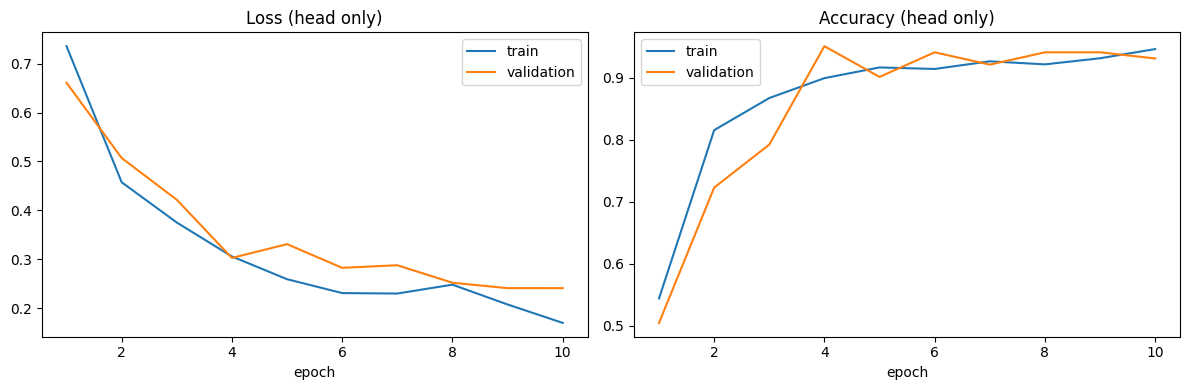

 not_sea_angel -> sea_angel      Thecosomata_f3af17a5-d6e1-4adc-acfa-e9865e34d5b0.png
 not_sea_angel -> sea_angel      water_128.png
 not_sea_angel -> sea_angel      water_108.png
 not_sea_angel -> sea_angel      Thecosomata_2002d16c-76dd-4536-b059-a0cc254994aa.png
 not_sea_angel -> sea_angel      Ctenophora_61dc66e8-dffb-4c9b-aed7-c6b50d843889.png
5 wrong out of 101 (95.0% accuracy)


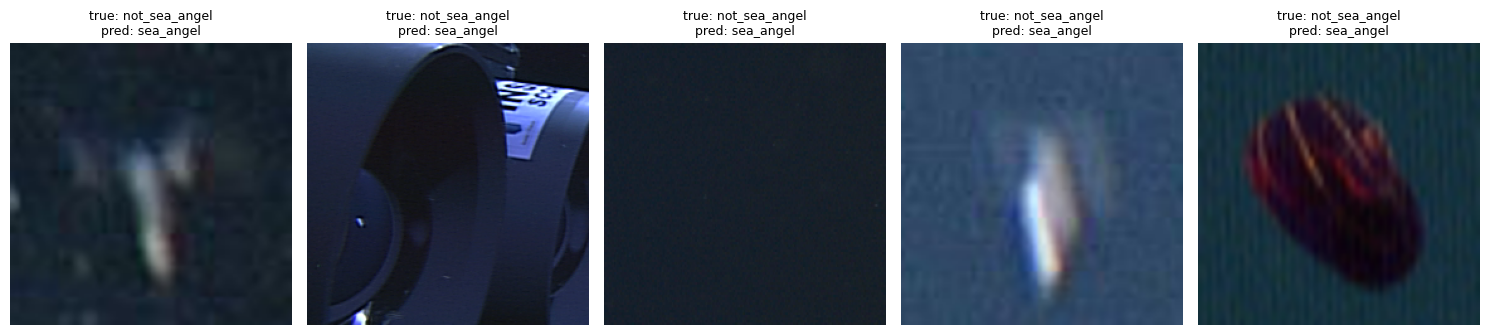

In [ ]:
names = {v: k for k, v in val_full.class_to_idx.items()}          # 0 -> not_sea_angel, 1 -> sea_angel
paths = [val_full.samples[i][0] for i in val_set.indices]          # file for each validation prediction


def plot_history(history, title=""):
    """Loss and accuracy per epoch, train vs validation."""
    tr_loss, va_loss, tr_acc, va_acc = zip(*history)
    epochs = range(1, len(history) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(epochs, tr_loss, label="train")
    ax1.plot(epochs, va_loss, label="validation")
    ax1.set(title=f"Loss {title}", xlabel="epoch")
    ax1.legend()
    ax2.plot(epochs, tr_acc, label="train")
    ax2.plot(epochs, va_acc, label="validation")
    ax2.set(title=f"Accuracy {title}", xlabel="epoch")
    ax2.legend()
    plt.tight_layout()
    plt.show()


def find_mistakes():
    """Score the current model on the validation set; return the wrong ones plus all predictions."""
    _, acc, p, l = run_epoch(val_loader, train=False)
    wrong = [(path, names[t], names[pr]) for path, t, pr in zip(paths, l, p) if t != pr]
    [print(f"{t:>14} -> {pr:<14} {os.path.basename(path)}") for path, t, pr in wrong]
    print(f"{len(wrong)} wrong out of {len(l)} ({acc:.1%} accuracy)")
    return wrong, p, l


def show_mistakes(wrong):
    """Show each wrong image with its true and predicted label."""
    n = max(len(wrong), 1)
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.5), squeeze=False)
    for ax, (path, true, pred) in zip(axes.flat, wrong):
        ax.imshow(Image.open(path))
        ax.set_title(f"true: {true}\npred: {pred}", fontsize=9)
    [ax.axis("off") for ax in axes.flat]
    plt.tight_layout()
    plt.show()


plot_history(history, "(head only)")
wrong, p, l = find_mistakes()
show_mistakes(wrong)

## 6. Look inside the model

### 6.1 Grad-CAM: where does it look?

Heatmaps showing which part of each image pushed the model toward "sea angel" (red = strong, blue =
ignored). Runs on every mistake plus 2 real sea angels, so you can compare. The heatmap comes from
ResNet's last 7×7 grid, so it shows a region, not exact pixels.

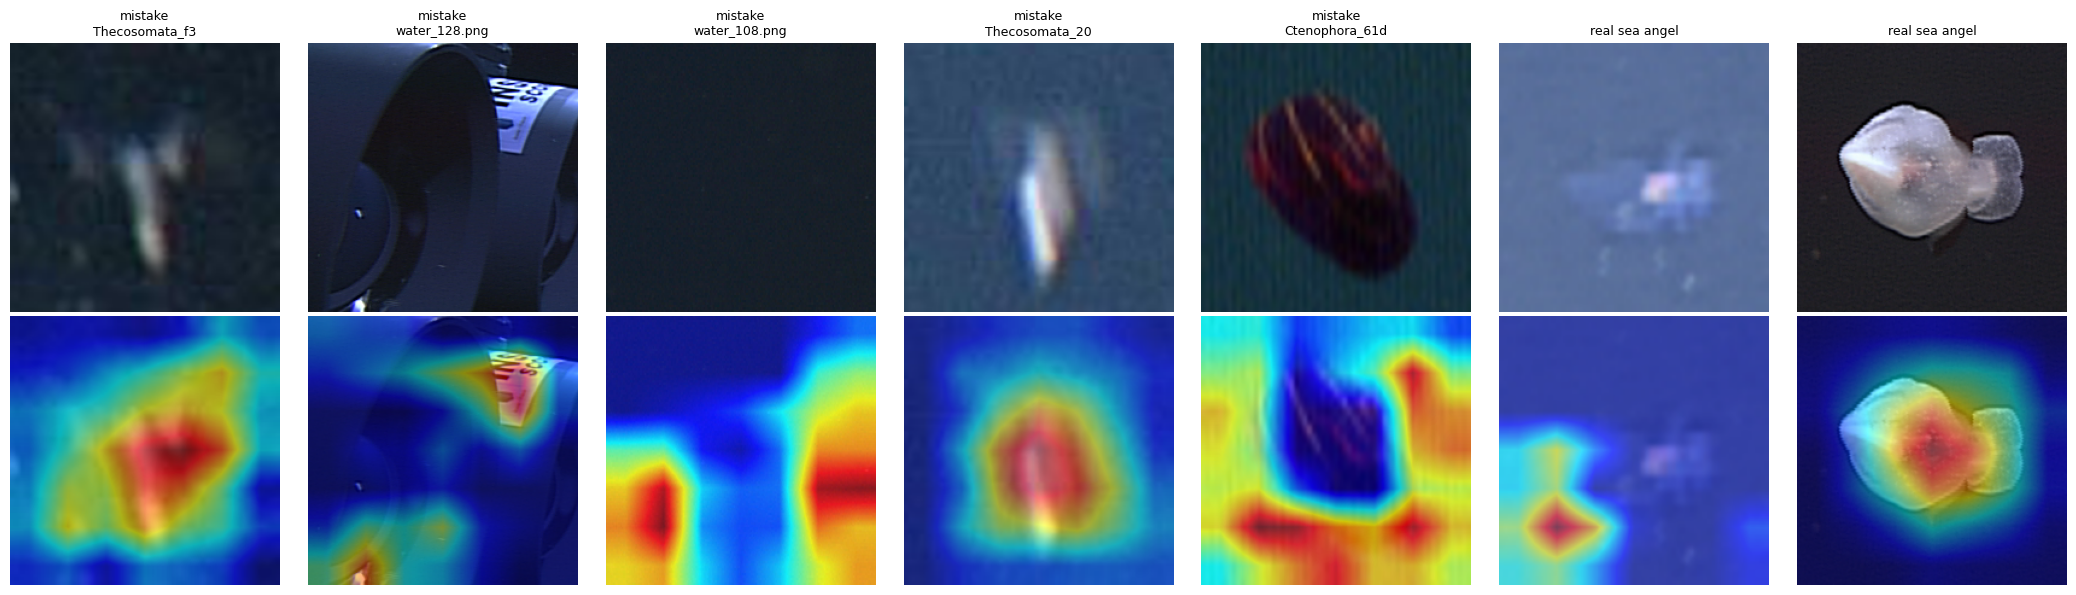

In [ ]:
def show_gradcam(paths, titles):
    """Original images on top, Grad-CAM heatmaps for the 'sea angel' class below."""
    model.eval()
    model.requires_grad_(True)                       # Grad-CAM needs gradients; no weights change here
    with GradCAM(model=model, target_layers=[model.layer4[-1]]) as cam:
        fig, axes = plt.subplots(2, len(paths), figsize=(3 * len(paths), 6), squeeze=False)
        for col, (path, title) in enumerate(zip(paths, titles)):
            img = Image.open(path).convert("RGB").resize((224, 224))
            rgb = np.array(img, dtype=np.float32) / 255.0
            x = val_tf(img).unsqueeze(0).to(device)
            gray = cam(input_tensor=x, targets=[ClassifierOutputTarget(1)])[0]
            axes[0, col].imshow(rgb)
            axes[0, col].set_title(title, fontsize=9)
            axes[1, col].imshow(show_cam_on_image(rgb, gray, use_rgb=True))
    [ax.axis("off") for ax in axes.flat]
    plt.tight_layout()
    plt.show()


# Keep this list so the same images can be compared after fine-tuning
real     = [path for path, t in zip(paths, l) if t == 1][:2]
examples = [path for path, _, _ in wrong] + real
titles   = [f"mistake\n{os.path.basename(path)[:14]}" for path, _, _ in wrong] + ["real sea angel"] * len(real)

show_gradcam(examples, titles)

### 6.2 Feature maps: what each layer sees

Passes one sea angel through the model and captures each stage's output with forward hooks. Early layers
still look like the photo (edges, brightness); deeper layers become small blocky grids that mark where
the important features are. Shows the 6 maps per layer with the strongest peak.

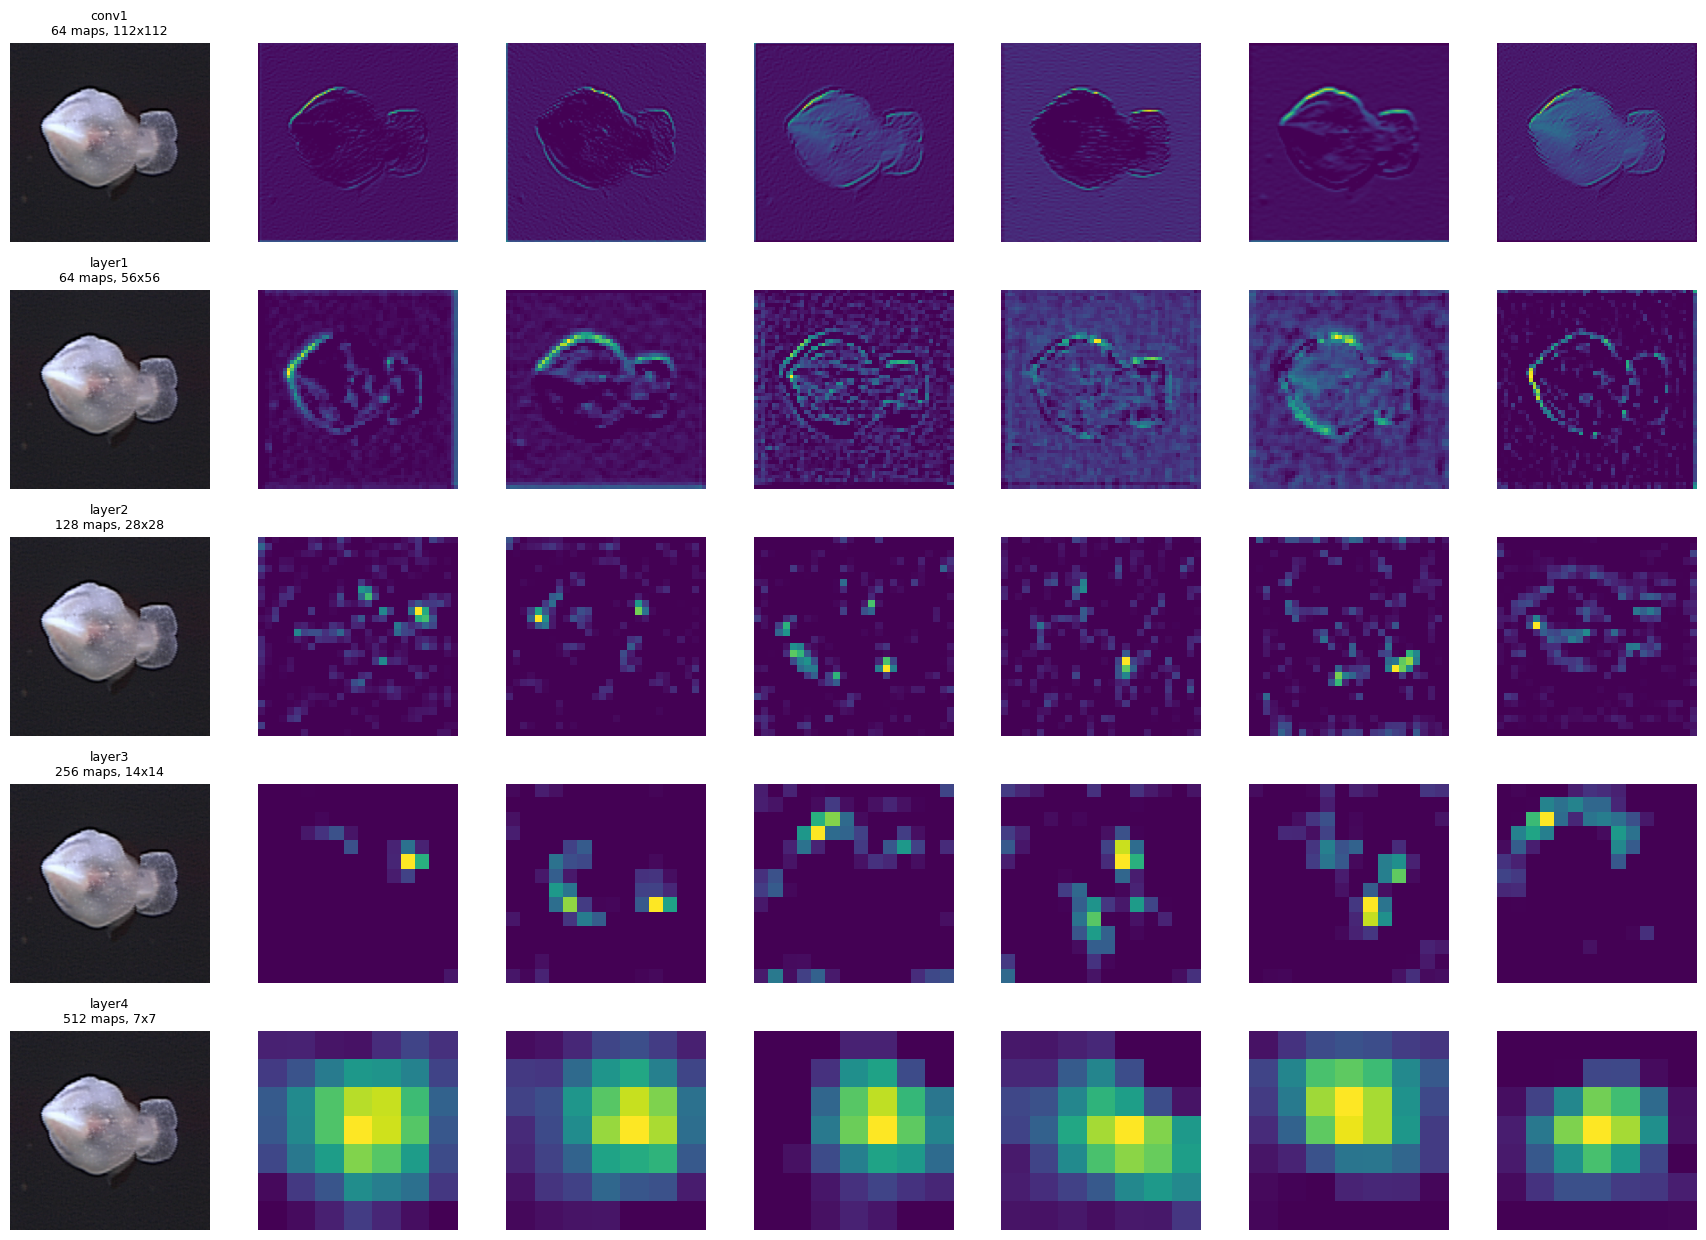

In [ ]:
def show_feature_maps(path, n_maps=6):
    """Original image plus the n_maps strongest feature maps from each stage of ResNet."""
    layers = {"conv1": model.relu, "layer1": model.layer1, "layer2": model.layer2,
              "layer3": model.layer3, "layer4": model.layer4}
    features = {}

    def save_output(name):
        def hook(module, inp, out):
            features[name] = out.detach().cpu()[0]
        return hook

    hooks = [layer.register_forward_hook(save_output(name)) for name, layer in layers.items()]
    img = Image.open(path).convert("RGB").resize((224, 224))
    with torch.no_grad():
        model(val_tf(img).unsqueeze(0).to(device))
    [h.remove() for h in hooks]                      # always remove hooks when done

    fig, axes = plt.subplots(len(layers), n_maps + 1, figsize=(2.5 * (n_maps + 1), 2.5 * len(layers)))
    for row, (name, fmap) in enumerate(features.items()):
        axes[row, 0].imshow(img)
        axes[row, 0].set_title(f"{name}\n{fmap.shape[0]} maps, {fmap.shape[1]}x{fmap.shape[2]}", fontsize=9)
        top = fmap.amax(dim=(1, 2)).argsort(descending=True)[:n_maps]
        [axes[row, col + 1].imshow(fmap[c], cmap="viridis") for col, c in enumerate(top)]
    [ax.axis("off") for ax in axes.flat]
    plt.tight_layout()
    plt.show()


fmap_path = real[-1]          # the second real sea angel is usually the clearer one
show_feature_maps(fmap_path)

## 7. Fine-tune deeper and compare

### 7.1 Unfreeze `layer4`

With only the head training, training accuracy levels off around 92%: the frozen ImageNet features
can't fully separate a sea angel from a comb jelly. This unfreezes ResNet's deepest layer group and
trains it with a very small learning rate, so it adapts what it knows instead of overwriting it. The
weights from before are saved in `frozen_state` for comparison.

In [ ]:
frozen_state = copy.deepcopy(model.state_dict())     # snapshot of the head-only model

model.requires_grad_(False)                          # refreeze (Grad-CAM unfroze everything)
model.layer4.requires_grad_(True)
model.fc.requires_grad_(True)

# New optimizer: tiny steps for the pretrained layer, larger steps for the head.
# run_epoch looks up the global `optimizer`, so it uses this one automatically.
optimizer = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-5},
    {"params": model.fc.parameters(),     "lr": 1e-4},
])
print(f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,} weights will train")

ft_history = fit(10)

8,394,754 weights will train
epoch  1 | train loss 0.275 acc 90.1% | val loss 0.263 acc 96.0% | precision 0.92 recall 1.00
epoch  2 | train loss 0.192 acc 93.1% | val loss 0.226 acc 96.0% | precision 0.92 recall 1.00
epoch  3 | train loss 0.164 acc 93.6% | val loss 0.204 acc 96.0% | precision 0.92 recall 1.00
epoch  4 | train loss 0.152 acc 94.6% | val loss 0.175 acc 96.0% | precision 0.92 recall 1.00
epoch  5 | train loss 0.142 acc 94.8% | val loss 0.148 acc 96.0% | precision 0.92 recall 1.00
epoch  6 | train loss 0.126 acc 96.3% | val loss 0.140 acc 96.0% | precision 0.92 recall 1.00
epoch  7 | train loss 0.118 acc 95.6% | val loss 0.124 acc 96.0% | precision 0.92 recall 1.00
epoch  8 | train loss 0.088 acc 97.3% | val loss 0.114 acc 96.0% | precision 0.92 recall 1.00
epoch  9 | train loss 0.082 acc 97.8% | val loss 0.108 acc 96.0% | precision 0.92 recall 1.00
epoch 10 | train loss 0.083 acc 96.8% | val loss 0.099 acc 95.0% | precision 0.93 recall 0.95
kept best epoch: 96.0%


### 7.2 Results after fine-tuning

Same curves and mistake list as before, now for the fine-tuned model.

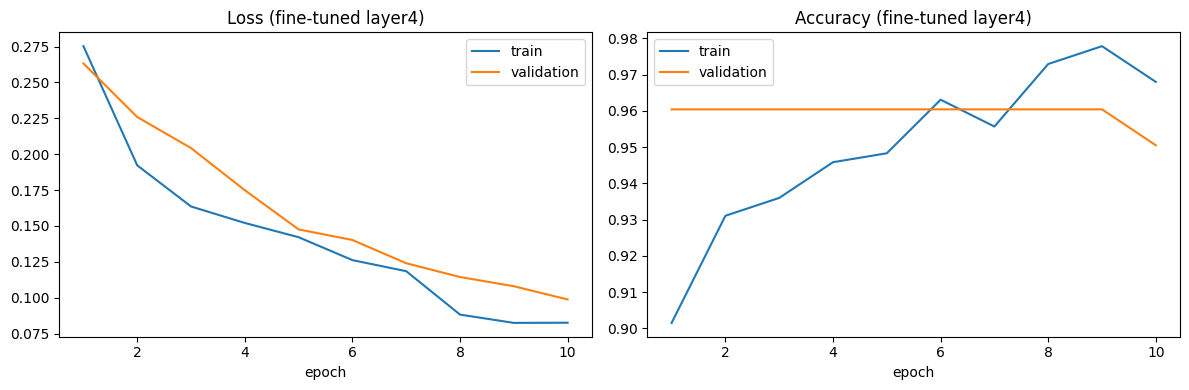

 not_sea_angel -> sea_angel      Thecosomata_f3af17a5-d6e1-4adc-acfa-e9865e34d5b0.png
 not_sea_angel -> sea_angel      water_128.png
 not_sea_angel -> sea_angel      Thecosomata_2002d16c-76dd-4536-b059-a0cc254994aa.png
 not_sea_angel -> sea_angel      Ctenophora_61dc66e8-dffb-4c9b-aed7-c6b50d843889.png
4 wrong out of 101 (96.0% accuracy)


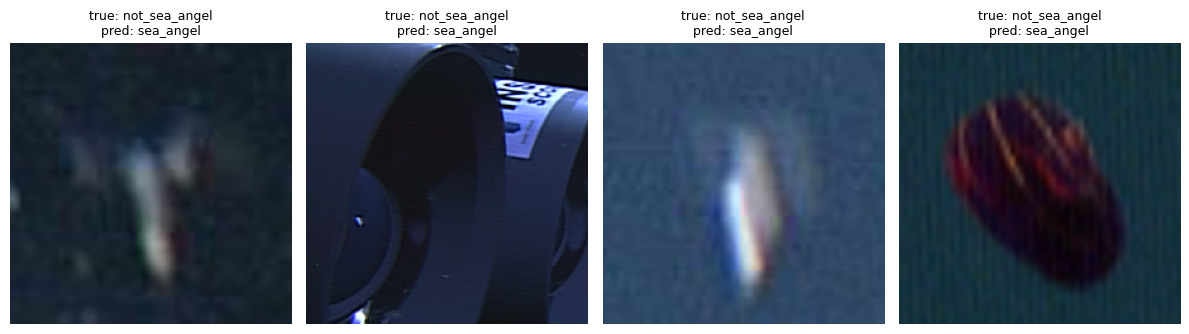

In [ ]:
plot_history(ft_history, "(fine-tuned layer4)")
wrong_ft, p_ft, l_ft = find_mistakes()
show_mistakes(wrong_ft)

### 7.3 Before vs. after: Grad-CAM and feature maps

Reruns the heatmaps on **the same images** as section 6.1, so you can see whether the model's attention
moved (for example from the glowing body toward the comb rows). Scroll up to 6.1 for the "before" row.

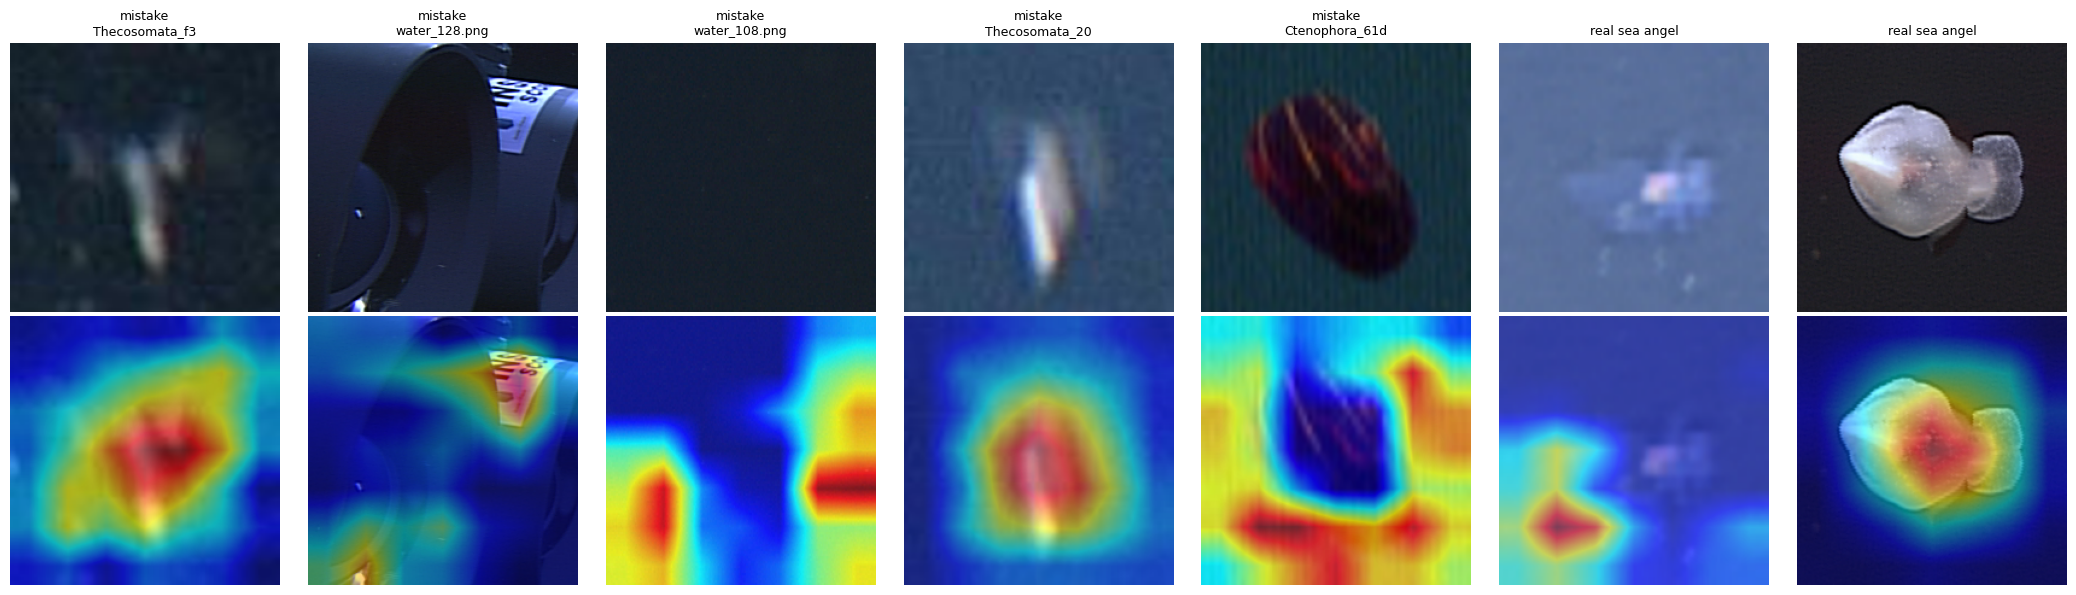

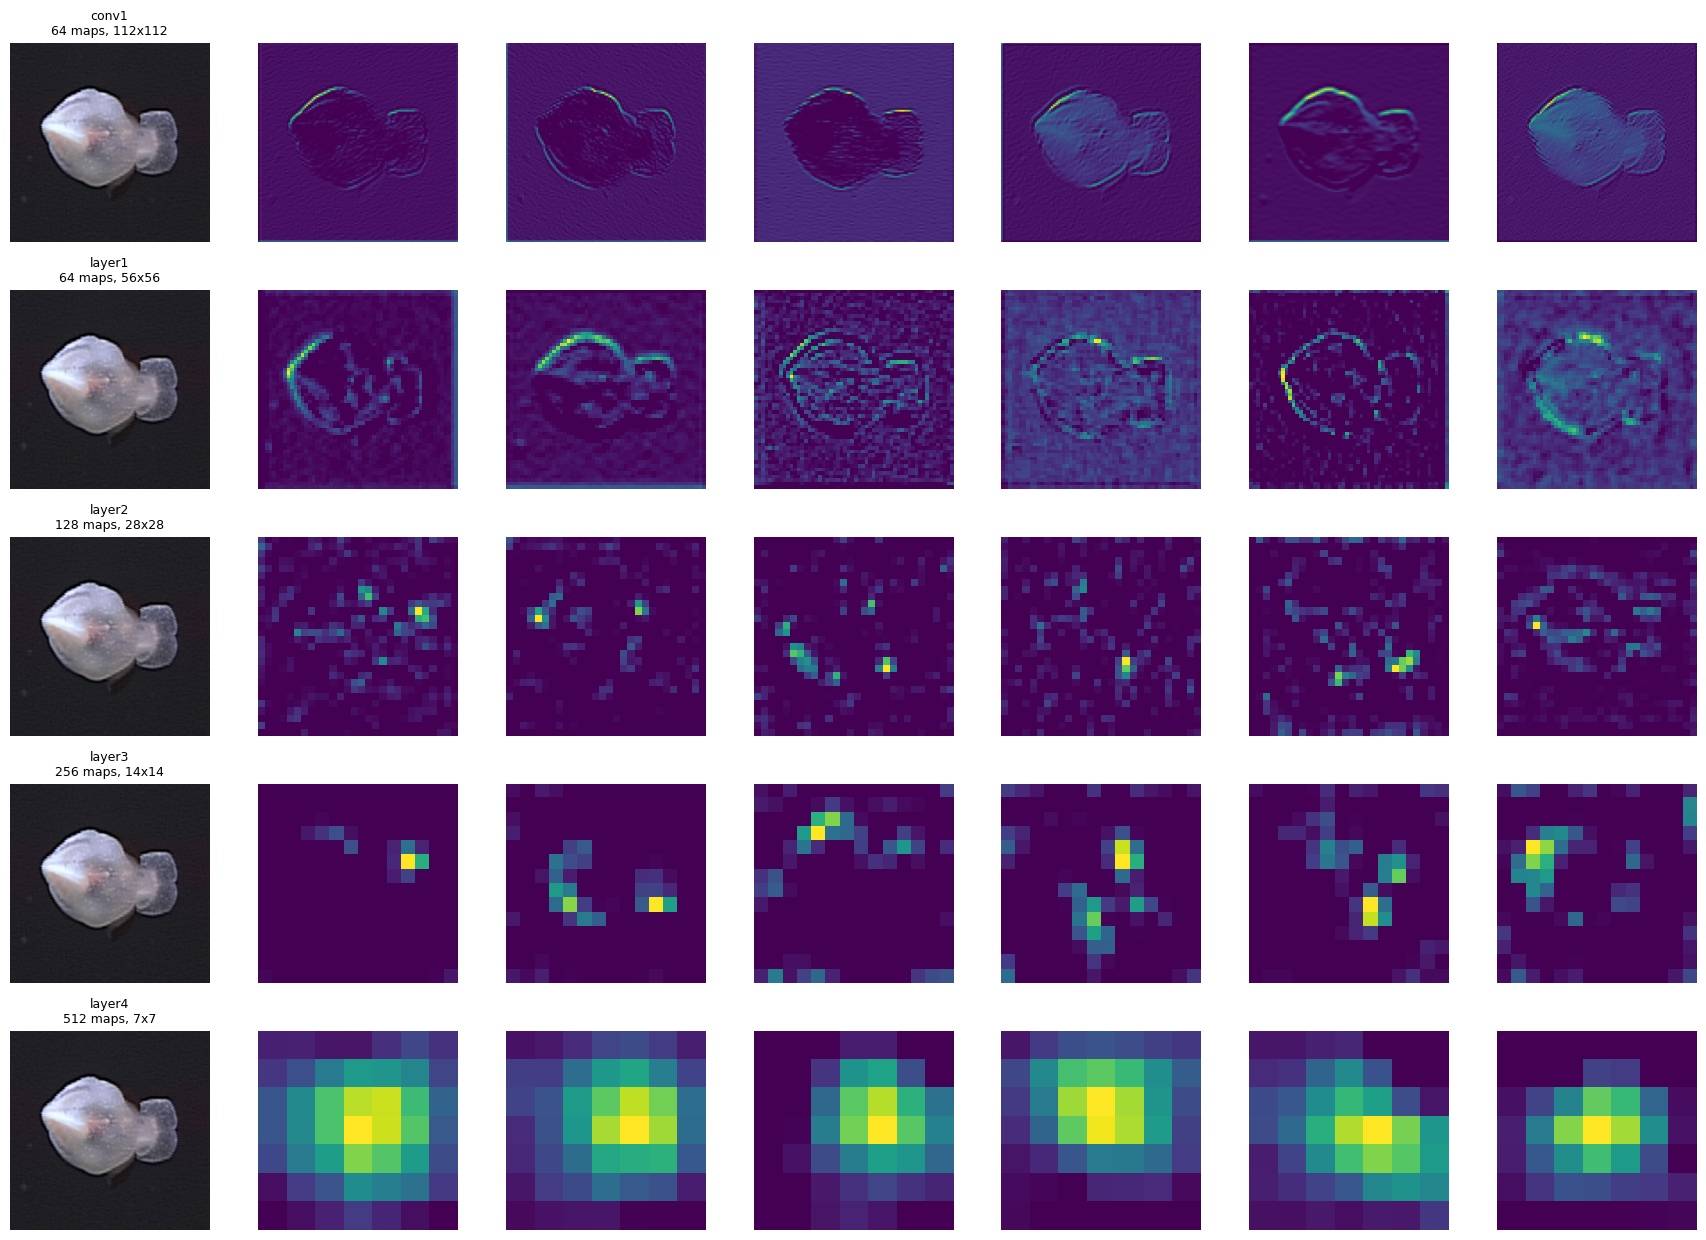

In [ ]:
show_gradcam(examples, titles)
show_feature_maps(fmap_path)

## 8. Save and reload

### 8.1 Save to Google Drive

Colab deletes `/content` when the runtime resets. This saves the fine-tuned weights, the head-only
weights, both training histories, the crops, and the COCO file to your Drive.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

save_dir = Path("/content/drive/MyDrive/sea_angel_project")
save_dir.mkdir(parents=True, exist_ok=True)

torch.save({
    "model_state": model.state_dict(),        # fine-tuned (best epoch)
    "frozen_state": frozen_state,             # head only, for before/after figures
    "class_to_idx": train_full.class_to_idx,
    "history": history,
    "ft_history": ft_history,
    "arch": "resnet18",
}, save_dir / "sea_angel_resnet18.pt")

!cp -r {CROP_DIR} "{save_dir}"
!cp {DATA_DIR}/dataset.json "{save_dir}"
print("saved to", save_dir)

ValueError: mount failed

### 8.2 Reload in a new session

Use this instead of retraining. First run **1. Setup** and **4. Prepare for training** (after copying the
crops back from Drive), then this cell. The structure must match the saved weights, so the 2-class head
is rebuilt before loading.

In [ ]:
# !cp -r /content/drive/MyDrive/sea_angel_project/crops /content/    # restore the crops first

save_dir = Path("/content/drive/MyDrive/sea_angel_project")
ckpt = torch.load(save_dir / "sea_angel_resnet18.pt", map_location=device)

model = models.resnet18()                            # empty structure, no pretrained weights
model.fc = nn.Linear(model.fc.in_features, 2)        # match the saved 2-class head
model.load_state_dict(ckpt["model_state"])
model = model.to(device).eval()
history, ft_history, frozen_state = ckpt["history"], ckpt["ft_history"], ckpt["frozen_state"]
loss_fn = nn.CrossEntropyLoss()                      # needed by run_epoch / find_mistakes